In [58]:
import numpy as np
import librosa
from scipy import signal
import plotly.express as px
from scipy.io import wavfile
import soundfile as sf
from pathlib import Path
from IPython.display import Audio, display

In [35]:
def read_wav_file(filename):
	Fs, x = wavfile.read(filename)
	print(f"file: {filename} Sampling frequency: {Fs} Hz", f"Number of samples: {x.shape} Duration: {x.shape[0]/Fs:.2f} s")
	return Fs, x



Fn1, n1 = read_wav_file("data/noise1.wav")
Fn2, n2 = read_wav_file("data/noise2.wav")
Fn3, n3 = read_wav_file("data/noise3.wav")
Fs, x = read_wav_file("data/music_clean.wav")

# Type fix
x = x.astype(np.float64)
n1 = n1.astype(np.float64)
n2 = n2.astype(np.float64)
n3 = n3.astype(np.float64)

file: data/noise1.wav Sampling frequency: 16000 Hz Number of samples: (140001,) Duration: 8.75 s
file: data/noise2.wav Sampling frequency: 16000 Hz Number of samples: (140001,) Duration: 8.75 s
file: data/noise3.wav Sampling frequency: 16000 Hz Number of samples: (140001,) Duration: 8.75 s
file: data/music_clean.wav Sampling frequency: 44100 Hz Number of samples: (237568,) Duration: 5.39 s


# Time Domain Visualisation

In [36]:
for i, (Fn, n) in enumerate([(Fn1, n1), (Fn2, n2), (Fn3, n3)], start=1):
    # Compute the FFT of the signal
	N = len(n)

	# Plot the time-domain signal
	px.line(x=np.arange(N)/Fn, y=n, title=f'Noise {i} - Time Domain', labels={'x': 'Time [s]', 'y': 'Amplitude'}).show()
px.line(x=np.arange(len(x))/Fs, y=x, title=f'Clean Music - Time Domain', labels={'x': 'Time [s]', 'y': 'Amplitude'}).show()

In [37]:
px.line(x=np.arange(len(x))/Fs, y=x, title=f'Clean Music - Time Domain', labels={'x': 'Time [s]', 'y': 'Amplitude'}).show()

# Simulation of noisy versions of the clean music

In [ ]:
# Function that generates a noisy version of the signal 
def noisy_signal(x, n, snr_db):
    # Adjusting the noise size to the music size
    x.astype(float)
    n.astype(float)
    lx = x.shape[0]
    repetitions = int(np.ceil(lx / len(n)))
    n = np.tile(n, repetitions)[:lx]
    
    # Average power of x
    Px = np.mean(x**2)
    
    # Average power of n
    Pn = np.mean(n**2)
    
    # Computing alpha
    alpha = np.sqrt(Px / (Pn * 10**(snr_db / 10)))
    
    # Computing the noisy signal with the adjusted noise
    y = x + alpha * n
    
    return y, Px, Pn, alpha

In [ ]:
# Computing y for each noise with a given SNR level
snr_db = [-5, 0, 5, 10, 20]

# Store results for every noise and SNR combination
noisy_signals = {}
signal_parameters = {}

noises = {
    "n1": n1,
    "n2": n2,
    "n3": n3
}

# Generate noisy signals for all noise types and SNR levels
for noise_name, noise in noises.items():
    noisy_signals[noise_name] = {}
    signal_parameters[noise_name] = {}

    for snr in snr_db:
        y, Px, Pn, alpha = noisy_signal(x, noise, snr)

        noisy_signals[noise_name][snr] = y
        signal_parameters[noise_name][snr] = {
            "Px": Px,
            "Pn": Pn,
            "alpha": alpha
        }
# Generate noisy signals for all noise types and SNR levels
y_signals = {}

for name, noise in {"n1": n1, "n2": n2, "n3": n3}.items():
    for snr in snr_db:
        y, Px, Pn, alpha = noisy_signal(x, noise, snr)
        y_signals[f"y_{name}_{snr}dB"] = y
        print(f"noisy music {f"y_{name}_{snr}dB"}:")
        display(Audio(y, rate=Fs))


noisy music y_n1_-5dB:


noisy music y_n1_0dB:


noisy music y_n1_5dB:


noisy music y_n1_10dB:


noisy music y_n1_20dB:


...

noisy music y_n3_-5dB:


noisy music y_n3_0dB:


noisy music y_n3_5dB:


noisy music y_n3_10dB:


noisy music y_n3_20dB:


In [80]:
# Parameters
n_fft = 1024 
hop_length = 256

# Parameters
n_fft = 1024
hop_length = 256

# STFT and magnitude for the 3 noisy signals
Y1 = librosa.stft(y1, n_fft=n_fft, hop_length=hop_length)
Y1_magnitude = np.abs(Y1)

Y2 = librosa.stft(y2, n_fft=n_fft, hop_length=hop_length)
Y2_magnitude = np.abs(Y2)

Y3 = librosa.stft(y3, n_fft=n_fft, hop_length=hop_length)
Y3_magnitude = np.abs(Y3)

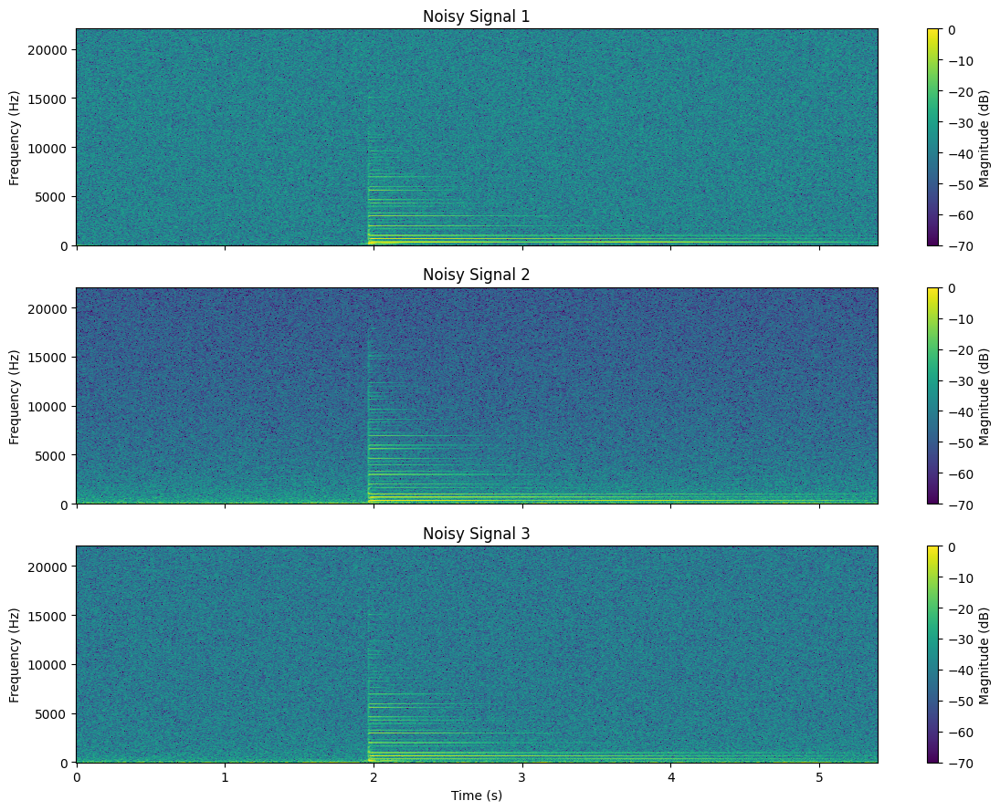

In [84]:
import matplotlib.pyplot as plt
import librosa
import numpy as np

# Use a common reference for all three spectrograms
common_ref = max(
    Y1_magnitude.max(),
    Y2_magnitude.max(),
    Y3_magnitude.max()
)

magnitudes_db = [
    librosa.amplitude_to_db(mag, ref=common_ref)
    for mag in [Y1_magnitude, Y2_magnitude, Y3_magnitude]
]

# Compute time and frequency axes
times = librosa.frames_to_time(
    np.arange(Y1.shape[1]), sr=Fs, hop_length=hop_length
)
freqs = librosa.fft_frequencies(sr=Fs, n_fft=n_fft)

# Plot the three spectrograms
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

for ax, Z, title in zip(
    axes,
    magnitudes_db,
    ["Noisy Signal 1", "Noisy Signal 2", "Noisy Signal 3"]
):
    im = ax.pcolormesh(
        times, freqs, Z,
        shading="auto",
        cmap="viridis",
        vmin=-70,
        vmax=0
    )
    ax.set_title(title)
    ax.set_ylabel("Frequency (Hz)")
    fig.colorbar(im, ax=ax, label="Magnitude (dB)")

axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()